In [30]:
import matplotlib.pyplot as plt
import random as r
import numpy as np

from pathlib import Path
from extractor import extract_mel_spectrogram

ROOT = Path.cwd()

## Single Mel Spectrogram

In [25]:
while not (ROOT / "datasets").exists():
    ROOT = ROOT.parent
dataset_path = ROOT / "datasets" / "fma" / "fma_large"
audio_files = list(dataset_path.rglob("*.mp3"))
print(f"Total Files Found : {len(audio_files)}")

Total Files Found : 106574


In [51]:
audio_path = r.choice(audio_files)

In [52]:
mel = extract_mel_spectrogram(audio_path)

In [53]:
print(mel.shape)

(128, 1293)


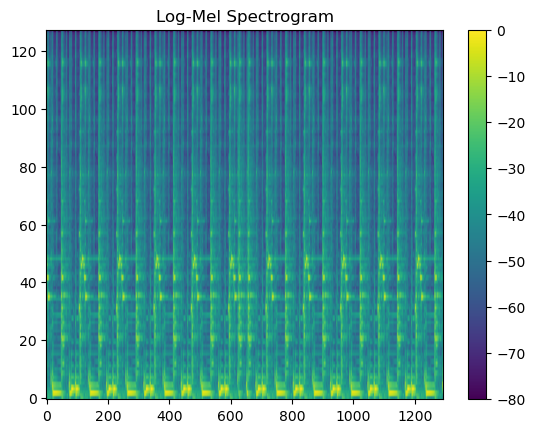

In [54]:
plt.imshow(mel, aspect="auto", origin="lower")
plt.colorbar()
plt.title("Log-Mel Spectrogram")
plt.show()

In [65]:
def slice_melspec(spec, token_width=45, stride=15):
    T = spec.shape[1]
    tokens = [
        np.pad(
            spec[:, i:i+token_width],
            ((0, 0), (0, max(0, token_width - spec[:, i:i+token_width].shape[1]))),
            mode='constant'
        )
        for i in range(0, T, stride)
    ]

    return tokens

In [66]:
tokens = slice_melspec(mel, token_width=45, stride=15)
print(f"Number of tokens: {len(tokens)}")
print(f"Single token shape: {tokens[0].shape}")

Number of tokens: 87
Single token shape: (128, 45)


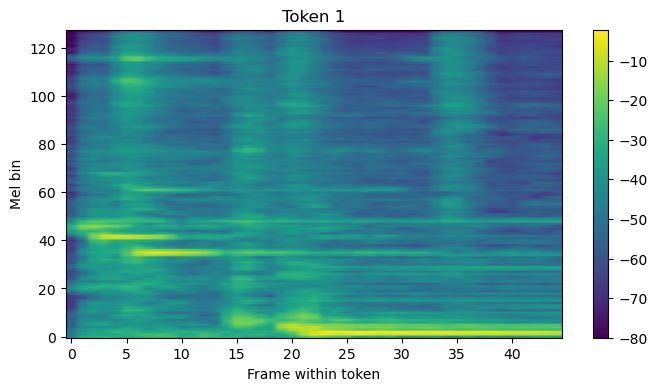

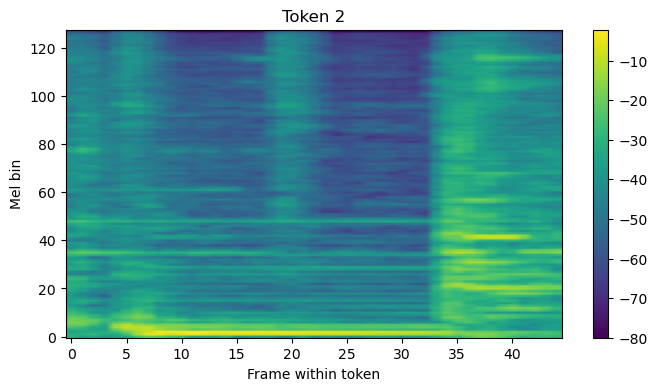

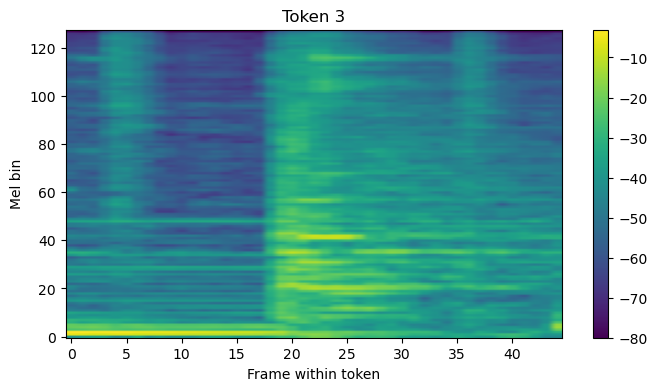

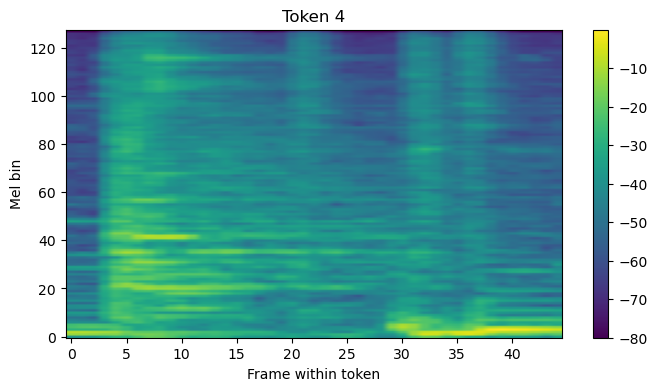

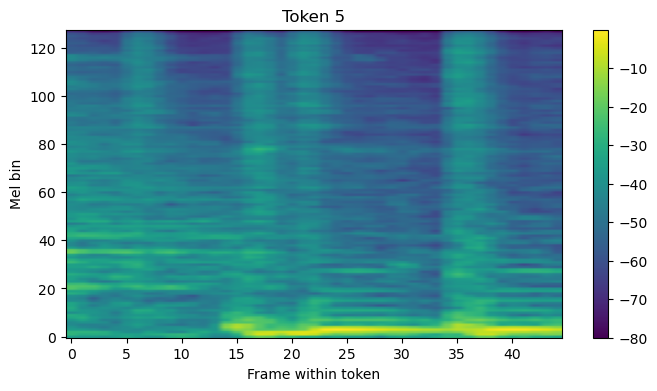

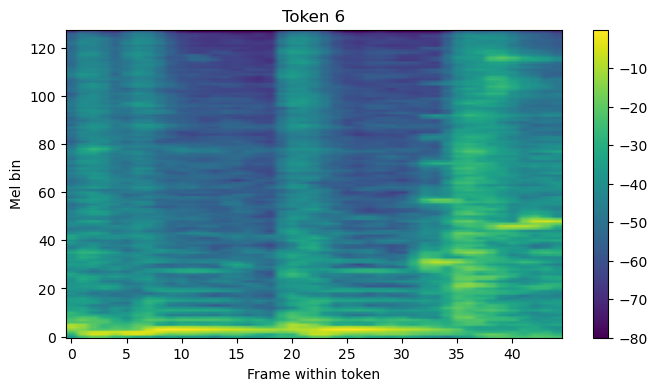

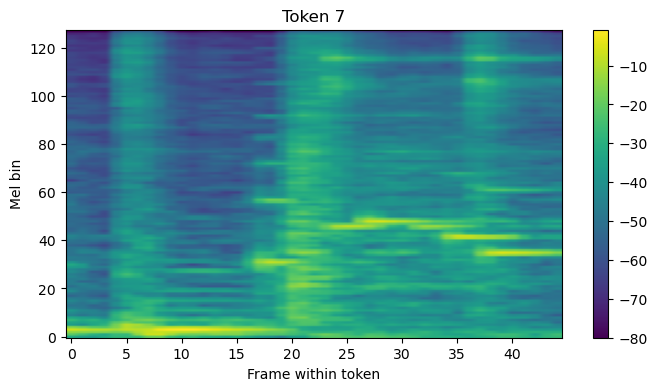

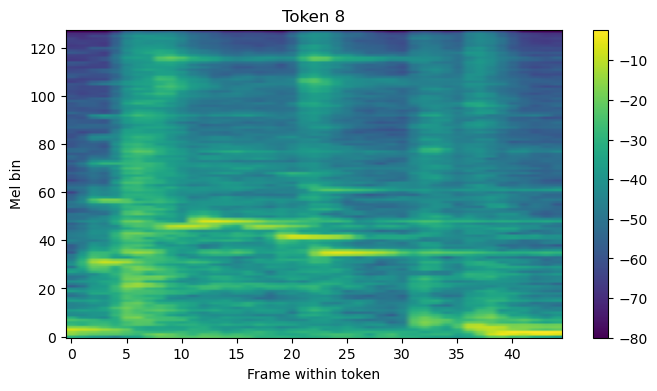

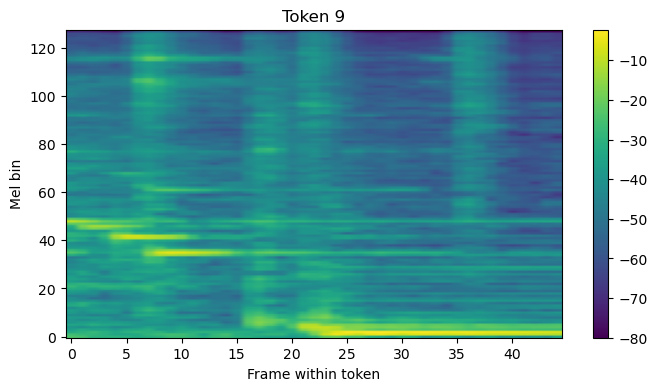

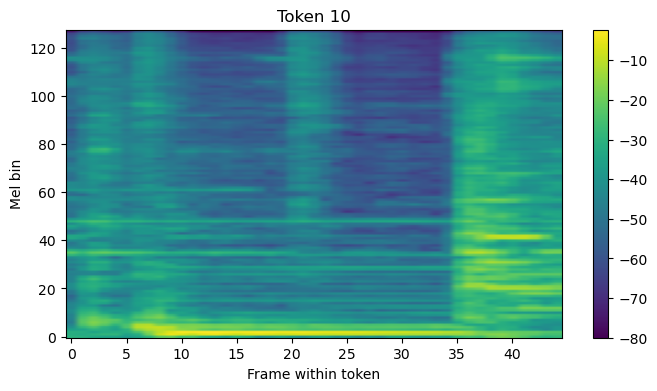

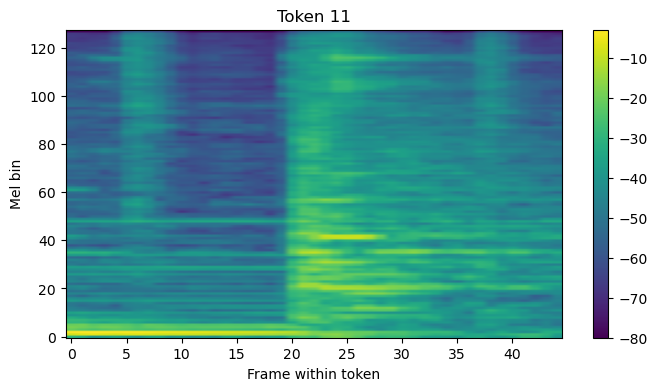

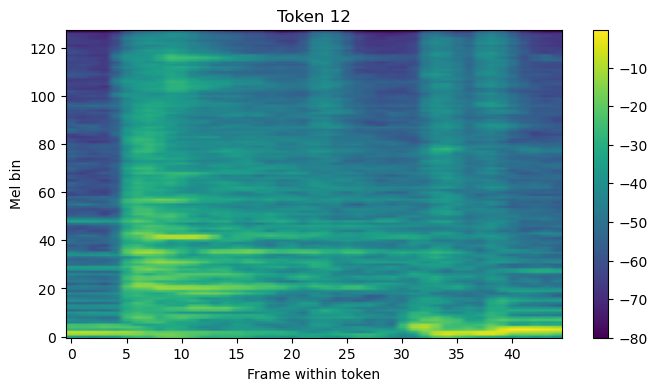

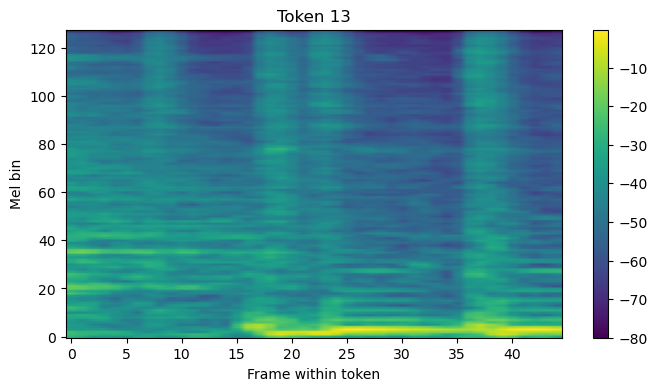

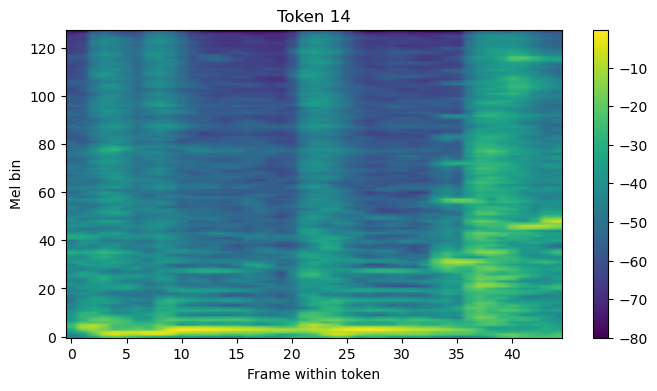

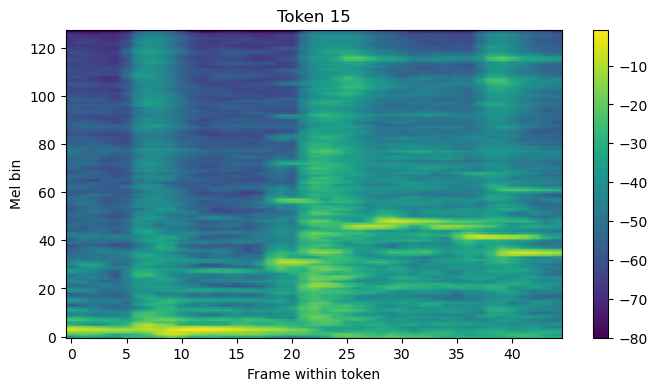

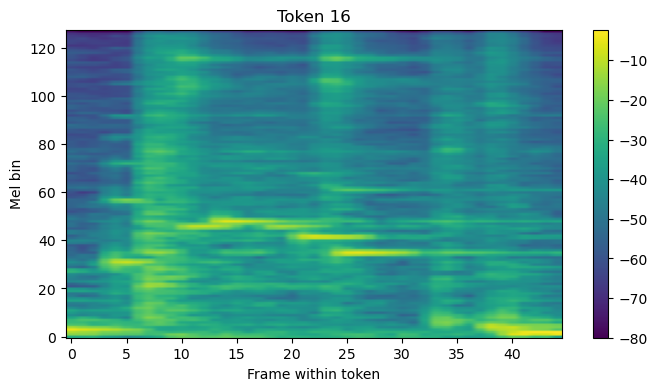

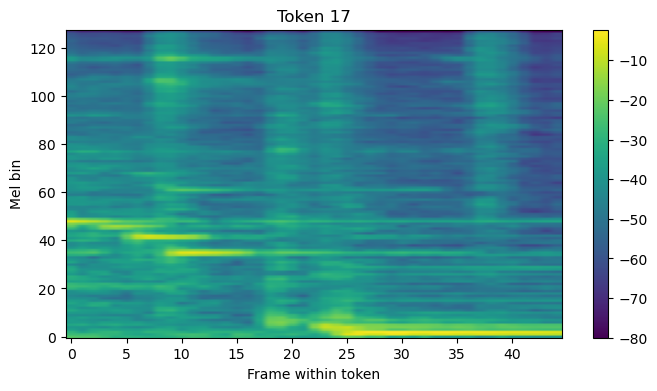

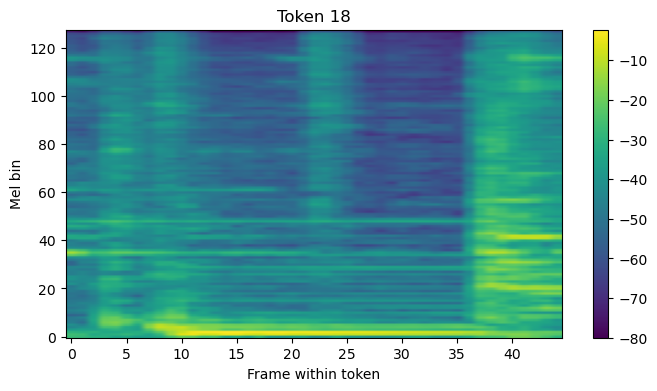

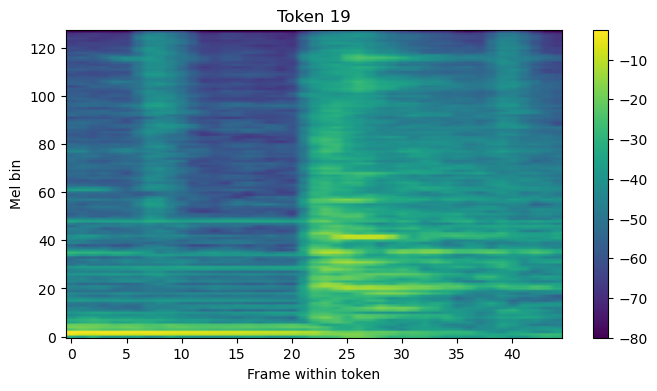

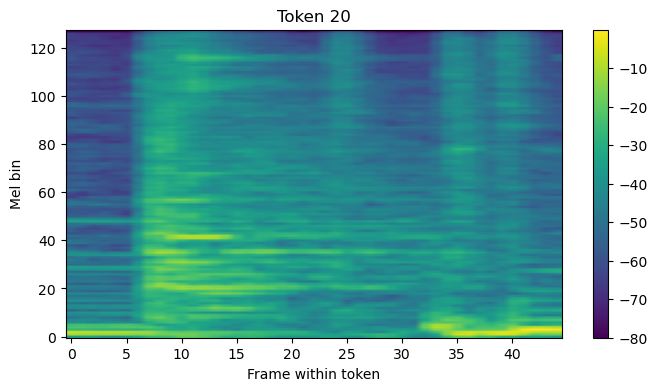

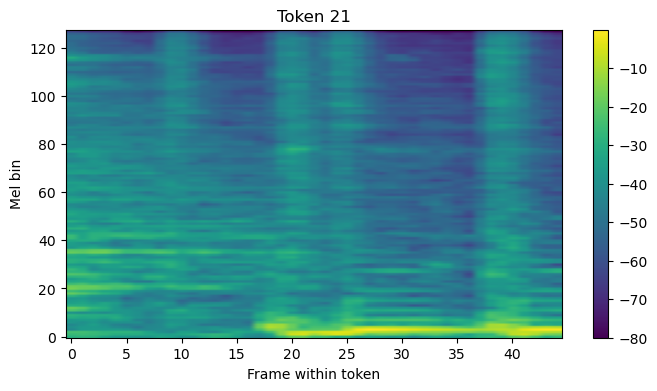

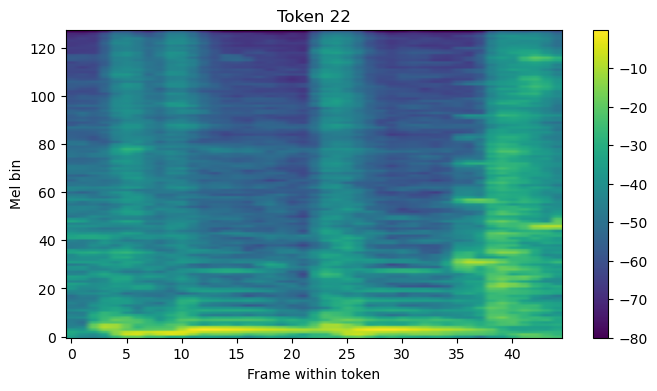

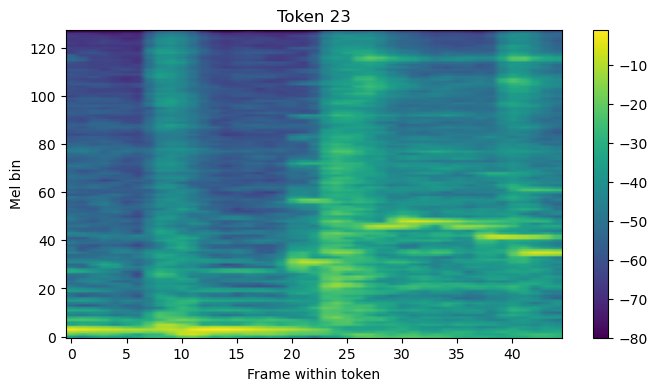

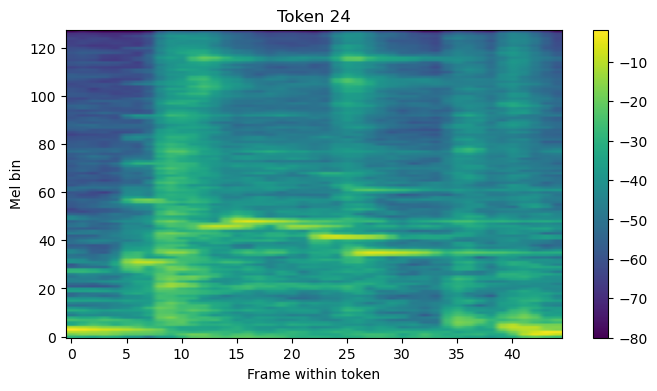

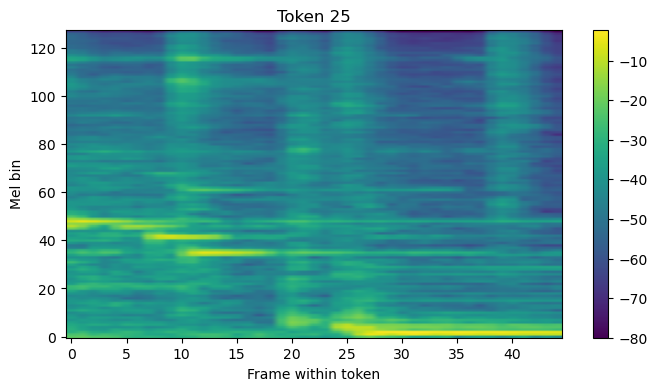

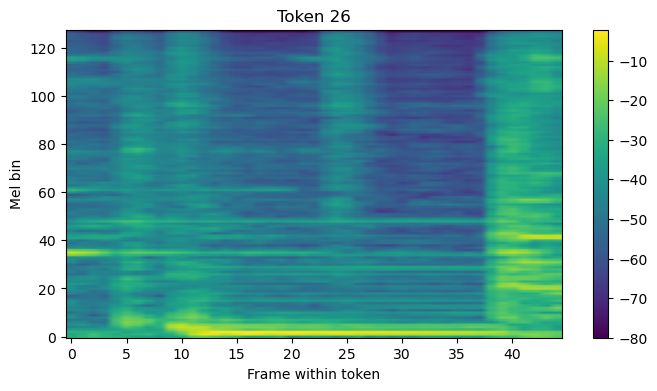

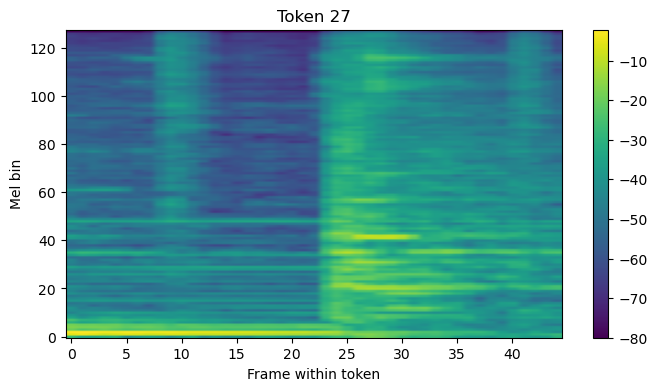

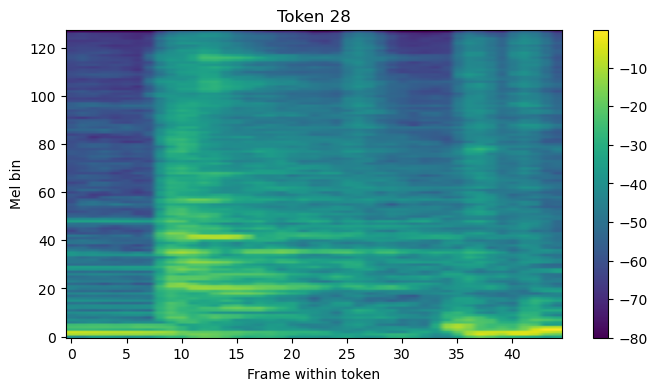

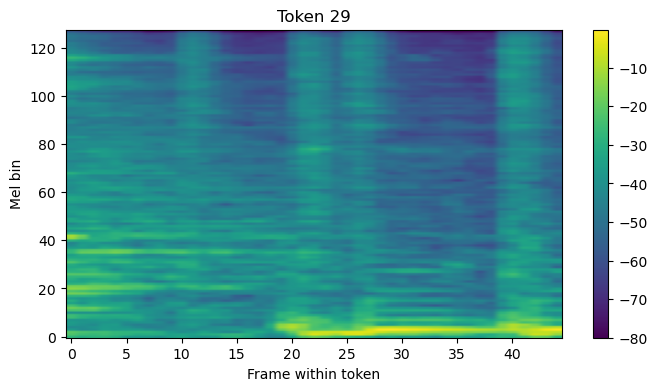

In [67]:
for idx in range(29):
    plt.figure(figsize=(8, 4))
    plt.imshow(tokens[idx], aspect="auto", origin="lower")
    plt.colorbar()
    plt.title(f"Token {idx + 1}")
    plt.xlabel("Frame within token")
    plt.ylabel("Mel bin")
    plt.show()

In [68]:
def token_stats(token):
    return {
        "mean": np.mean(token),
        "std": np.std(token),
        "max": np.max(token),
        "min": np.min(token),
    }

In [69]:
for i in tokens:
    print(token_stats(i))

{'mean': -46.361427, 'std': 10.804397, 'max': -2.2240868, 'min': -80.0}
{'mean': -44.494194, 'std': 12.07888, 'max': -2.2240868, 'min': -80.0}
{'mean': -44.745304, 'std': 11.692886, 'max': -3.0704536, 'min': -80.0}
{'mean': -43.27118, 'std': 11.153228, 'max': -0.03147888, 'min': -80.0}
{'mean': -46.62946, 'std': 10.72988, 'max': -0.03147888, 'min': -80.0}
{'mean': -44.770573, 'std': 12.14453, 'max': -0.03147888, 'min': -80.0}
{'mean': -43.64989, 'std': 11.782191, 'max': -0.79639435, 'min': -80.0}
{'mean': -42.02714, 'std': 10.522382, 'max': -2.270977, 'min': -80.0}
{'mean': -45.440002, 'std': 10.40648, 'max': -2.270977, 'min': -80.0}
{'mean': -44.773937, 'std': 12.033553, 'max': -2.270977, 'min': -80.0}
{'mean': -44.832493, 'std': 11.748298, 'max': -3.0443459, 'min': -80.0}
{'mean': -43.367104, 'std': 11.209386, 'max': -0.19090652, 'min': -80.0}
{'mean': -46.173862, 'std': 10.623339, 'max': -0.19090652, 'min': -80.0}
{'mean': -45.056454, 'std': 12.190696, 'max': -0.19090652, 'min': -80

In [72]:
def plot_hist(domain):
    plt.figure(figsize=(8, 5))
    plt.hist(domain, bins=20)
    plt.title("Distribution of Token Mean Energy")
    plt.xlabel("Mean dB")
    plt.ylabel("Frequency")
    plt.show()

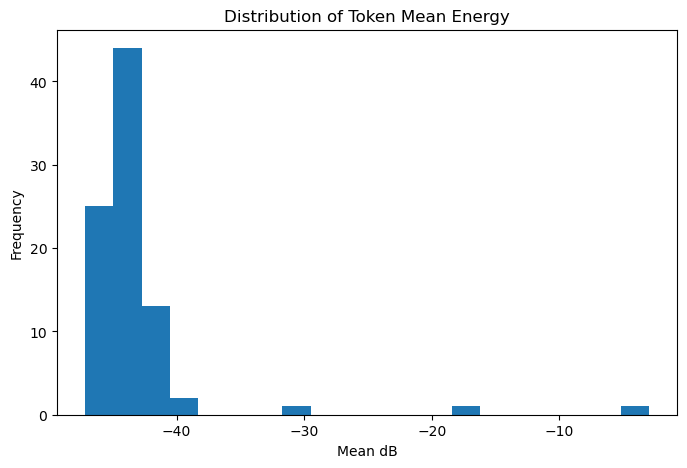

In [73]:
means = [np.mean(t) for t in tokens]
plot_hist(means)

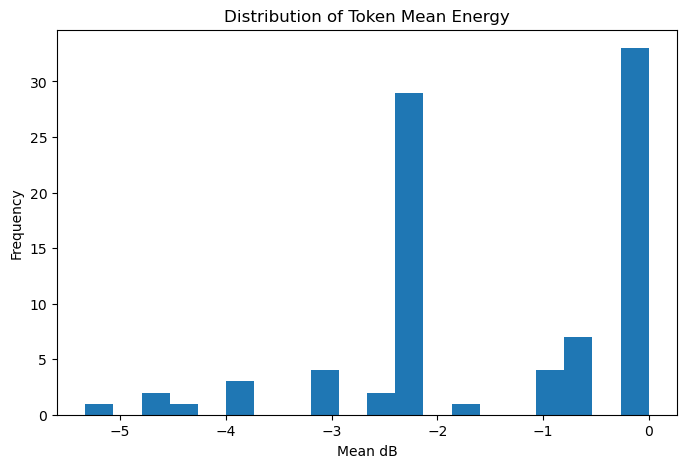

In [74]:
maxs = [np.max(t) for t in tokens]
plot_hist(maxs)

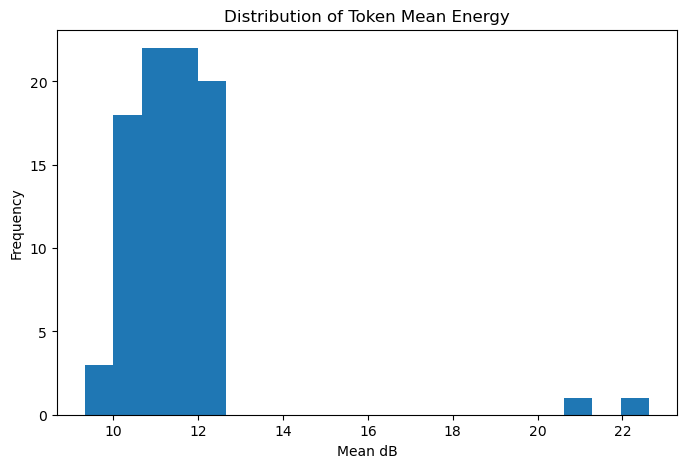

In [75]:
stds = [np.std(t) for t in tokens]
plot_hist(stds)